In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
from glob import glob
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Concatenate


from google.colab import drive
drive.mount('/content/drive')
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Mounted at /content/drive
True
Tesla T4


In [2]:
import zipfile
import os

# 壓縮檔路徑（改成你實際的檔名）
ZIP_PATH = '/content/drive/MyDrive/dataset_github.zip'
# 解壓縮目標路徑
EXTRACTED_PATH = '/content/dataset_unzip'

# 確保目標路徑存在
os.makedirs(EXTRACTED_PATH, exist_ok=True)

# 解壓縮 zip 檔案
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACTED_PATH)

# 假設解壓縮後的資料夾名稱（依實際情況調整）
DATA_ROOT = os.path.join(EXTRACTED_PATH, 'dataset_github')

print(f'資料已成功解壓縮至：{EXTRACTED_PATH}')
print(f'資料根目錄為：{DATA_ROOT}')


資料已成功解壓縮至：/content/dataset_unzip
資料根目錄為：/content/dataset_unzip/dataset_github


In [3]:
import zipfile
import os

# 壓縮檔路徑（改成你實際的檔名）
ZIP_PATH = '/content/drive/MyDrive/CNN_INPUT0409.zip'
# 解壓縮目標路徑
EXTRACTED_PATH = '/content/CNN_INPUT0409'

# 確保目標路徑存在
os.makedirs(EXTRACTED_PATH, exist_ok=True)

# 解壓縮 zip 檔案
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACTED_PATH)

# 假設解壓縮後的資料夾名稱（依實際情況調整）
DATA_ROOT = os.path.join(EXTRACTED_PATH, 'CNN_INPUT0409')

print(f'資料已成功解壓縮至：{EXTRACTED_PATH}')
print(f'資料根目錄為：{DATA_ROOT}')


資料已成功解壓縮至：/content/CNN_INPUT0409
資料根目錄為：/content/CNN_INPUT0409/CNN_INPUT0409


In [4]:
import os
import glob
import torch
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit

# ================= 1. 設定正確的絕對路徑 =================
CSV_FILE = '/content/dataset_unzip/dataset_github/REF.csv'
NPY_DIR = '/content/CNN_INPUT0409/CNN_INPUT0409'

print(f"讀取 CSV 路徑: {CSV_FILE}")
print(f"讀取 NPY 路徑: {NPY_DIR}")

# ================= 2. 讀取並標記 CSV =================
df = pd.read_csv(CSV_FILE)



normal_list  = [ 34, 35, 37, 44, 45, 47, 48, 49, 51, 52, 53, 54, 55,
                     56, 57, 58, 59, 63, 65, 66, 67, 68, 69, 71, 72, 77, 78, 79, 81, 82,
                     83, 84, 85, 86, 87, 88, 89, 92, 95, 96, 99, 100, 101, 102, 103, 104,
                     116, 121, 122 ]
abnormal_list  = [36, 38, 39, 40, 41, 42, 43,
                  46, 50, 60, 61, 62, 64, 70, 73, 74, 75, 76, 80, 90, 91, 93, 94, 97,
                  98, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 117, 118,
                  119, 120, 123, 124, 125]
df['label'] = -1
df.loc[df['number'].isin(normal_list), 'label'] = 0
df.loc[df['number'].isin(abnormal_list), 'label'] = 1

# ================= 3. 將 NPY 檔案與 CSV 配對 =================
print("\n正在配對實體檔案與標籤...")
npy_files = glob.glob(os.path.join(NPY_DIR, '*.npy'))
data_list = []

for file_path in npy_files:
    filename = os.path.basename(file_path)

    # 🌟 改用 '_seg_' 來切斷字串
    record_name = filename.split('_seg_')[0]

    match_row = df[df['file'] == record_name]

    if not match_row.empty:
        patient_number = match_row['number'].values[0]
        label = match_row['label'].values[0]

        if label in [0, 1]:
            data_list.append({
                'file_path': file_path,
                'record_name': record_name,
                'number': patient_number,
                'label': label
            })

df_data = pd.DataFrame(data_list)
print(f"✅ 成功配對了 {len(df_data)} 個有效片段！")

if len(df_data) == 0:
    print("⚠️ 警告：沒有成功配對任何檔案，請檢查 NPY 檔名與 REF.csv 的 file 欄位是否一致。")
else: # 🌟 修正了縮排錯誤，以下要在 else 裡面執行
    # ================= 4. Blind Test 分組 (Train 70%, Val 15%, Test 15%) =================
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
    train_idx, temp_idx = next(gss1.split(df_data, groups=df_data['number']))

    df_train_temp = df_data.iloc[train_idx].reset_index(drop=True)
    df_temp = df_data.iloc[temp_idx].reset_index(drop=True)

    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
    val_idx, test_idx = next(gss2.split(df_temp, groups=df_temp['number']))

    df_val_temp = df_temp.iloc[val_idx].reset_index(drop=True)
    df_test_temp = df_temp.iloc[test_idx].reset_index(drop=True)

    # ================= 新增：不改變資料比例 (維持原樣) =================
    def keep_original_dataframe(df_split, split_name):
        final_0 = len(df_split[df_split['label'] == 0])
        final_1 = len(df_split[df_split['label'] == 1])

        # 為了與其他函數的輸出格式保持一致，我們這裡只做打亂 (shuffle)，絕對不刪除資料
        df_original = df_split.sample(frac=1, random_state=42).reset_index(drop=True)

        print(f"[{split_name}] 維持原樣 -> 總數: {len(df_original)} | 正常(0): {final_0} | 異常(1): {final_1}")
        return df_original

    print("\n⚖️ 不進行資料平衡 (維持原始資料比例)...")
    df_train = keep_original_dataframe(df_train_temp, "Train")
    df_val = keep_original_dataframe(df_val_temp, "Val")
    df_test = keep_original_dataframe(df_test_temp, "Test")

    # ================= 5. 定義 PyTorch Dataset =================
    class ECGPCGDataset(Dataset):
        def __init__(self, dataframe):
            self.dataframe = dataframe

        def __len__(self):
            return len(self.dataframe)

        def __getitem__(self, idx):
            file_path = self.dataframe.iloc[idx]['file_path']
            label = self.dataframe.iloc[idx]['label']

            data = np.load(file_path)

            # 🌟 補回 Z-score 標準化 (非常重要，防止機率變 1.0 和 0.0)
            mean = np.mean(data)
            std = np.std(data)
            if std > 1e-8:
                data = (data - mean) / std
            else:
                data = data - mean

            tensor_data = torch.tensor(data, dtype=torch.float32)
            tensor_label = torch.tensor(label, dtype=torch.long)
            return tensor_data, tensor_label

    # ================= 6. 建立 DataLoader =================
    BATCH_SIZE = 32
    train_loader = DataLoader(ECGPCGDataset(df_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(ECGPCGDataset(df_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader = DataLoader(ECGPCGDataset(df_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    print("\n🎉 恭喜！DataLoader 準備完畢，資料維持原始比例且已標準化，符合 Blind Test！")

    # 測試一下取出的資料形狀
    for x, y in train_loader:
        print(f"👉 測試 Batch 輸出維度 - 影像: {x.shape}, 標籤: {y.shape}")
        print(f"👉 測試 Batch 數值範圍 - 最大值: {x.max().item():.4f}, 最小值: {x.min().item():.4f}")
        zero_cnt = (y == 0).sum().item()
        one_cnt = (y == 1).sum().item()
        print(f"👉 該 Batch 內部標籤分佈 - 正常(0): {zero_cnt}, 異常(1): {one_cnt}")
        break

讀取 CSV 路徑: /content/dataset_unzip/dataset_github/REF.csv
讀取 NPY 路徑: /content/CNN_INPUT0409/CNN_INPUT0409

正在配對實體檔案與標籤...
✅ 成功配對了 8750 個有效片段！

⚖️ 不進行資料平衡 (維持原始資料比例)...
[Train] 維持原樣 -> 總數: 6417 | 正常(0): 2525 | 異常(1): 3892
[Val] 維持原樣 -> 總數: 965 | 正常(0): 556 | 異常(1): 409
[Test] 維持原樣 -> 總數: 1368 | 正常(0): 671 | 異常(1): 697

🎉 恭喜！DataLoader 準備完畢，資料維持原始比例且已標準化，符合 Blind Test！
👉 測試 Batch 輸出維度 - 影像: torch.Size([32, 2, 720]), 標籤: torch.Size([32])
👉 測試 Batch 數值範圍 - 最大值: 3.1799, 最小值: -5.4407
👉 該 Batch 內部標籤分佈 - 正常(0): 13, 異常(1): 19


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import time

# ================= 1. 定義 1D 版本的 VGG16 =================
class VGG16_1D(nn.Module):
    def __init__(self, num_classes=2):
        super(VGG16_1D, self).__init__()

        # 卷積層特徵萃取 (完全仿照 VGG16 的 Block 架構)
        self.features = nn.Sequential(
            # Block 1: 輸入長度 720 -> 經過 MaxPool 變成 360
            nn.Conv1d(2, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(64, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2, stride=2),

            # Block 2: 360 -> 180
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(128, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2, stride=2),

            # Block 3: 180 -> 90
            nn.Conv1d(128, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(256, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(256, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2, stride=2),

            # Block 4: 90 -> 45
            nn.Conv1d(256, 512, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(512, 512, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(512, 512, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2, stride=2),

            # Block 5: 45 -> 22 (720連續除以2五次，取整數為22)
            nn.Conv1d(512, 512, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(512, 512, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(512, 512, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2, stride=2),
        )

        # 全連接層分類器
        self.classifier = nn.Sequential(
            nn.Linear(512 * 22, 4096), # 展平後的維度
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5), # 防止 Overfitting
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, num_classes) # 輸出 2 類 (正常 / 異常)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1) # Flatten (展平)
        x = self.classifier(x)
        return x

# ================= 2. 初始化模型、損失函數與優化器 =================
# 自動偵測是否可以使用 GPU (Colab 上記得把 Runtime 改成 T4 GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"目前使用的運算設備: {device}")

model = VGG16_1D(num_classes=2).to(device)



目前使用的運算設備: cuda


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score
import time
import torch
import torch.nn as nn

# ================= 2.5 處理資料不平衡   =================

criterion = nn.CrossEntropyLoss() # 分類問題標準 Loss
optimizer = optim.Adam(model.parameters(), lr=0.0001) # Learning Rate 可以之後再調

weights = torch.tensor([1.0, 1.3], dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

# ================= 3. 開始訓練 (Training Loop 升級版) =================
num_epochs =5

# 用來記錄最佳的 F1 分數，以便儲存最佳模型
best_val_f1 = 0.0
best_model_path = '/content/best_RESNET18_model.pth'

print("\n🚀 開始訓練 RESNET18_1D 模型 (包含 Recall/F1 監控與模型儲存)...")
for epoch in range(num_epochs):
    start_time = time.time()

    # ================== 訓練階段 ==================
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels) # 這裡算出來的 Loss 已經包含我們剛剛設定的權重了

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_acc = train_correct / train_total
    train_loss = train_loss / train_total

    # ================== 驗證階段 ==================
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    # 用來收集驗證集所有預測結果與真實標籤，計算 F1 等指標
    all_val_preds = []
    all_val_labels = []

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

            # 收集起來算 sklearn 指標
            all_val_preds.extend(predicted.cpu().numpy())
            all_val_labels.extend(labels.cpu().numpy())

    val_acc = val_correct / val_total
    val_loss = val_loss / val_total

    # 計算驗證集的 Precision, Recall, F1 (使用 macro 平均)
    val_precision = precision_score(all_val_labels, all_val_preds, average='macro', zero_division=0)
    val_recall = recall_score(all_val_labels, all_val_preds, average='macro', zero_division=0)
    val_f1 = f1_score(all_val_labels, all_val_preds, average='macro', zero_division=0)

    end_time = time.time()

    # 印出每個 Epoch 的結果
    print(f"Epoch [{epoch+1}/{num_epochs}] | Time: {end_time - start_time:.1f}s")
    print(f"  [Train] Loss: {train_loss:.4f} | Acc: {train_acc*100:.2f}%")
    print(f"  [Val]   Loss: {val_loss:.4f} | Acc: {val_acc*100:.2f}% | Recall: {val_recall*100:.2f}% | F1: {val_f1*100:.2f}%")

    # ================== 儲存最佳模型 ==================
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)
        print(f"  🌟 驗證集 F1 創新高 ({val_f1*100:.2f}%)，已儲存當前最佳模型權重！")

print("\n🎉 訓練迴圈結束！")

# 訓練結束後，自動把表現最好的權重載入回模型中，以便後續測試
model.load_state_dict(torch.load(best_model_path))
print("✅ 已載入 Validation 表現最佳的模型權重，準備進行最終測試。")


🚀 開始訓練 RESNET18_1D 模型 (包含 Recall/F1 監控與模型儲存)...
Epoch [1/5] | Time: 13.3s
  [Train] Loss: 0.0398 | Acc: 98.54%
  [Val]   Loss: 2.5551 | Acc: 64.25% | Recall: 63.51% | F1: 63.48%
  🌟 驗證集 F1 創新高 (63.48%)，已儲存當前最佳模型權重！
Epoch [2/5] | Time: 13.0s
  [Train] Loss: 0.0411 | Acc: 98.44%
  [Val]   Loss: 1.8302 | Acc: 73.78% | Recall: 72.85% | F1: 72.98%
  🌟 驗證集 F1 創新高 (72.98%)，已儲存當前最佳模型權重！
Epoch [3/5] | Time: 12.9s
  [Train] Loss: 0.0359 | Acc: 98.72%
  [Val]   Loss: 2.1041 | Acc: 63.73% | Recall: 63.03% | F1: 62.98%
Epoch [4/5] | Time: 12.7s
  [Train] Loss: 0.0372 | Acc: 98.60%
  [Val]   Loss: 2.5424 | Acc: 63.52% | Recall: 62.01% | F1: 62.10%
Epoch [5/5] | Time: 12.4s
  [Train] Loss: 0.0545 | Acc: 98.10%
  [Val]   Loss: 1.2080 | Acc: 74.51% | Recall: 74.68% | F1: 74.24%
  🌟 驗證集 F1 創新高 (74.24%)，已儲存當前最佳模型權重！

🎉 訓練迴圈結束！
✅ 已載入 Validation 表現最佳的模型權重，準備進行最終測試。


🔍 開始在未見過的測試集 (Test Set) 上獲取預測機率...

📊 測試結果 (Test Metrics):
Accuracy  (準確率): 61.99%
Precision (精確率): 62.65%
Recall    (召回率): 62.18%
F1-Score  (F1分數): 61.69%

📝 詳細分類報告 (Classification Report):
              precision    recall  f1-score   support

  Normal (0)       0.59      0.72      0.65       671
Abnormal (1)       0.66      0.52      0.58       697

    accuracy                           0.62      1368
   macro avg       0.63      0.62      0.62      1368
weighted avg       0.63      0.62      0.62      1368



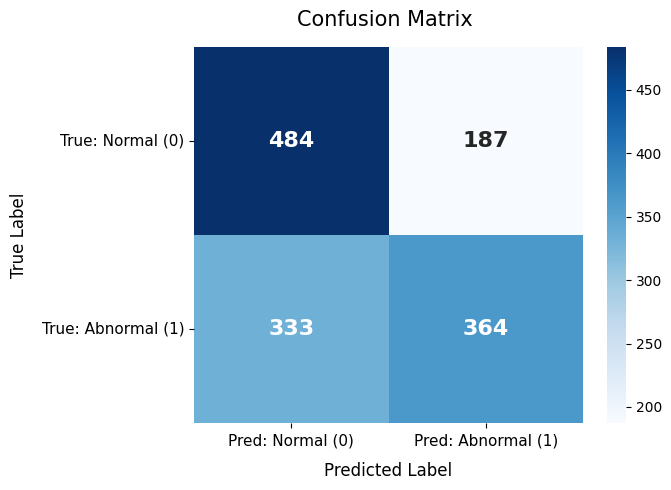

In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch

# ================= 1. 取得模型輸出的機率 (只跑一次 Inference) =================
print("🔍 開始在未見過的測試集 (Test Set) 上獲取預測機率...")

model.eval()
all_probs = []  # 🌟 這次我們存的是「機率」，而不是最終預測的 0 或 1
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)

        # 將輸出轉換為 0~1 的機率
        probabilities = torch.softmax(outputs, dim=1)

        # 只取出猜測為「Abnormal (1)」的機率
        prob_abnormal = probabilities[:, 1]

        # 存入 List
        all_probs.extend(prob_abnormal.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 將 List 轉為 Numpy 陣列方便後續計算
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)


thresholds_to_test = [0.97]

for threshold in thresholds_to_test:
    print("=" * 60)

    current_preds = (all_probs > threshold).astype(int)

    # 計算評估指標
    acc = accuracy_score(all_labels, current_preds)
    precision = precision_score(all_labels, current_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, current_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, current_preds, average='macro', zero_division=0)

    print("\n📊 測試結果 (Test Metrics):")
    print(f"Accuracy  (準確率): {acc * 100:.2f}%")
    print(f"Precision (精確率): {precision * 100:.2f}%")
    print(f"Recall    (召回率): {recall * 100:.2f}%")
    print(f"F1-Score  (F1分數): {f1 * 100:.2f}%")

    print("\n📝 詳細分類報告 (Classification Report):")
    print(classification_report(all_labels, current_preds, target_names=['Normal (0)', 'Abnormal (1)'], zero_division=0))

    # 畫出混淆矩陣
    cm = confusion_matrix(all_labels, current_preds)

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                annot_kws={"size": 16, "weight": "bold"},
                xticklabels=['Pred: Normal (0)', 'Pred: Abnormal (1)'],
                yticklabels=['True: Normal (0)', 'True: Abnormal (1)'])

    # 動態標題，會顯示目前畫的是哪個閾值的結果
    plt.title(f'Confusion Matrix ', fontsize=15, pad=15)
    plt.xlabel('Predicted Label', fontsize=12, labelpad=10)
    plt.ylabel('True Label', fontsize=12, labelpad=10)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11, rotation=0)

    plt.tight_layout()
    plt.show()
    print("\n\n") # 空兩行，讓下一個閾值的輸出分開一點